# 08 Model-based operator offset ratio (question 3)

The twin design (notebook 07) cannot run: no passive object flies near the Starlink shells. Here each
active satellite is its own control and the physics model gives the storm loss (`src/offset_model.py`).

For every active satellite (rows not flagged `free_drag`, outside orbit changes) and every storm:

- **predicted storm loss** = sum over the window of (MSIS 2.1 with actual ap - MSIS 2.1 with the storm's
  quiet ap) x dt, with the satellite's catalog-scaled B;
- **observed storm loss** = sum over the window of (observed decay - the satellite's own baseline over
  days -10..-3) x dt;
- windows: ducking (main_onset to recovery_end) and recovery (next 10 days);
- **offset = 1 - observed / predicted** (ratio of sums over all storm-satellite pairs), per window and
  total; 95% CIs from a storm-clustered wild bootstrap (Webb weights).

All 20 storms (no clean-window rule), with and without May / Oct 2024. Storms close together share no
rows: each storm's windows end at the next storm's main_onset, and rows linked to another storm get no
predicted loss (their counterfactual is that storm's quiet ap). One more run drops the storms whose quiet
ap (days -10..-3) is over 1.5x the storm-free median: an earlier storm sits in that window. Model-error correction from the
passive cohort's Y_residual by storm class and altitude band. Placebo: free-drag Starlinks.
Question 3 is a Starlink study: all 21 satellites used here are Starlinks.

In [1]:
import sys
from pathlib import Path

import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import offset_model as om
from src import plots
from src.omni_io import load_spaceweather
from src.schema import load_table
from src.storms import load_storms

RESULTS = ROOT / "results"
table = load_table()
storms = load_storms()
sw = load_spaceweather()
out = om.run(table, storms, n_boot=999, seed=0, sw=sw)    # same as python -m src.causal_run
pairs = out["pairs"]
print(f"{len(pairs)} storm-satellite pairs, {pairs['norad_id'].nunique()} satellites, "
      f"{pairs['storm_id'].nunique()} storms")

278 storm-satellite pairs, 21 satellites, 20 storms


## 1. Which rows count

Rows flagged `free_drag` (notebook 07) are out. On top of that, `orbit_change_flags` drops rows inside a
21-day window whose net altitude change is more than 1 km either way: orbit raises and shell changes
(STARLINK-30105 is raised from 444 to 481 km in March 2025) are operator moves unrelated to storms, and
they swamped the recovery window (+-20-37 km) in a first run.

In [2]:
active = table[(table["is_active"] == 1) & (table["free_drag"] == 0)]
flags = om.orbit_change_flags(active)
print(f"orbit-change rows: {int(flags.sum())} of {len(active)}")
active[flags == 1].groupby("object_name").size()

orbit-change rows: 533 of 12835


object_name
STARLINK-1010      47
STARLINK-1013      43
STARLINK-1015     129
STARLINK-30105    203
STARLINK-30254     40
STARLINK-30275     71
dtype: int64

## 2. Passive model error used for the correction (m/day, Y_residual window minus pre)

In [3]:
e = out["errors"]
e[e["band"].isin(["400-500", "500-600"]) | e["band"].isna()].round(2)

,storm_class,band,window,delta,n_objects,n_storms
0,extreme,400-500,duck,-9.40,5,1
1,extreme,400-500,rec,-12.77,5,1
2,extreme,500-600,duck,-7.93,24,1
3,extreme,500-600,rec,-14.96,24,1
8,moderate,400-500,duck,-2.88,5,11
9,moderate,400-500,rec,2.94,5,11
10,moderate,500-600,duck,-4.39,24,11
11,moderate,500-600,rec,4.21,24,11
16,severe,400-500,duck,8.48,5,2
17,severe,400-500,rec,-0.66,5,2


MSIS 2.1 under-predicts storm decay for moderate / strong / extreme storms at 400-600 km (delta -3 to
-15 m/day) and over-predicts for the two severe storms (+6 to +8). The correction moves the predicted
loss accordingly; the 400-500 km band rests on only 5 passive objects.

## 3. Offset ratios

In [4]:
out["summary"].round(3)

est   ci_lo  \
storms                               prediction  statistic                     
all storms                           uncorrected offset_duck   1.212   1.095   
                                                 offset_rec    2.446 -24.734   
                                                 offset_total  1.194   0.772   
                                                 duck_part     1.231   1.111   
                                                 rec_part     -0.037  -0.468   
                                     corrected   offset_duck   1.199   1.086   
                                                 offset_rec    0.350  -7.067   
                                                 offset_total  1.173   0.975   
                                                 duck_part     1.163   1.053   
                                                 rec_part      0.011  -0.215   
without 3,4,11                       uncorrected offset_duck   1.246   1.054   
                                                 offset_rec    1.035  -0.743   
                                                 offset_total  1.272   1.080   
                                                 duck_part     1.400   1.185   
                                                 rec_part     -0.129  -0.354   
                                     corrected   offset_duck   1.227   1.055   
                                                 offset_rec    1.041  -1.009   
                                                 offset_total  1.245   1.079   
                                                 duck_part     1.346   1.157   
                                                 rec_part     -0.101  -0.305   
quiet ap (without 10,15,16,17,19,20) uncorrected offset_duck   1.193   1.080   
                                                 offset_rec    0.972  -0.093   
                                                 offset_total  1.167   1.050   
                                                 duck_part     1.050   0.951   
                                                 rec_part      0.116  -0.011   
                                     corrected   offset_duck   1.183   1.074   
                                                 offset_rec    0.980   0.237   
                                                 offset_total  1.151   1.044   
                                                 duck_part     0.997   0.905   
                                                 rec_part      0.154   0.037   

                                                                ci_hi      se  \
storms                               prediction  statistic                      
all storms                           uncorrected offset_duck    1.336   0.062   
                                                 offset_rec    30.653  14.138   
                                                 offset_total   1.636   0.225   
                                                 duck_part      1.357   0.063   
                                                 rec_part       0.378   0.216   
                                     corrected   offset_duck    1.314   0.059   
                                                 offset_rec     6.986   3.774   
                                                 offset_total   1.363   0.103   
                                                 duck_part      1.274   0.057   
                                                 rec_part       0.213   0.115   
without 3,4,11                       uncorrected offset_duck    1.433   0.099   
                                                 offset_rec     2.844   0.933   
                                                 offset_total   1.457   0.097   
                                                 duck_part      1.611   0.111   
                                                 rec_part       0.092   0.116   
                                     corrected   offset_duck    1.402   0.091   
                                              

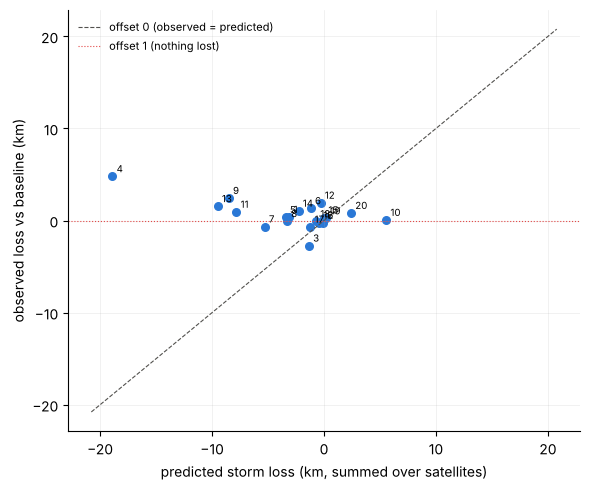

In [5]:
plots.plot_offset_model_storms(pairs, storms, out_path=RESULTS / "offset_model_storms.png");

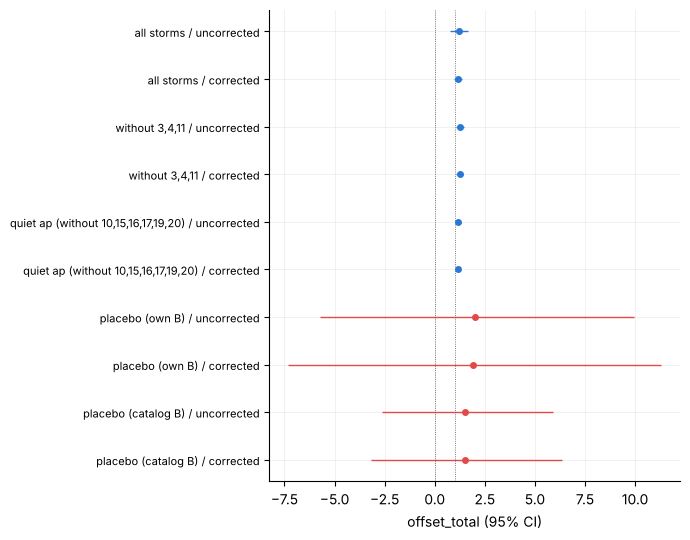

In [6]:
plots.plot_offset_model_summary(out["summary"], out["placebo"], out_path=RESULTS / "offset_model_summary.png");

- **Total offset 1.19 (95% CI 0.77 to 1.64)**, corrected 1.17 (0.98 to 1.36); without May / Oct 2024
  1.27 (1.08 to 1.46). The Starlinks lose no more altitude around storms than in their pre-storm baseline:
  the whole predicted storm loss is undone.
- The uncorrected interval is wide because of storms 10, 12 and 20: their recovery windows have a
  *positive* predicted loss (actual ap below the quiet ap), and storms 10 and 20 have a quiet ap of 18
  (an earlier storm in days -10..-3). Without the 6 storms whose quiet ap is not quiet (10, 15, 16, 17, 19,
  20): **1.17 (1.05 to 1.29)**, corrected 1.15 (1.04 to 1.26). The proper fix is a quiet ap from storm-free
  days in physics.quiet_ap_drivers, which needs the drivers rebuilt.
- It happens during the storm: ducking window 1.21 (1.10 to 1.34), ducking part of the total 1.23; the
  recovery part is -0.04 (-0.47 to 0.38), so there is nothing left to climb back. (Before storms stopped
  sharing rows the recovery part was 0.12: most of it was the May 10 superstorm counted again in the May 2
  storm's recovery window.)
- Values above 1 mean the satellites decayed a little *less* than their baseline. This is not TLE noise:
  on storm-free dates the 3-day observed loss is about -1 m per satellite (SD 29 m), while in the larger
  storms it is +80 to +160 m. It is either thrust that overshoots or a TLE mean-element artifact (a jump in
  drag shifts the fitted mean motion); TLEs cannot tell them apart, so read it as "at least a full offset".
  A dented baseline does not explain it: the 6 storms whose days -10..-3 are free of other storms give a
  ducking offset of 1.20.
- Per storm (figure): observed loss stays near zero whatever the prediction. May 2024 (storm 4) was
  predicted to cost ~19 km summed over the satellites; they ended ~5 km above baseline. Storm 3 (May 2)
  is the one clear loss (~2.7 km against ~1.3 km predicted).
- The recovery-window ratio (1 - O_rec / P_rec) is meaningless here: the predicted loss after recovery_end
  is near zero and changes sign across storms. The additive parts are the readable split.


## 4. Drag-sensitivity scale

In [7]:
out["b_sensitivity"].round(3)

b_scale,0.75,1.25
offset_duck,1.283,1.170
offset_rec,2.928,2.157
offset_total,1.258,1.155
duck_part,1.303,1.188
rec_part,-0.045,-0.033


The predicted loss scales with B (catalog x 0.71-0.77). If the true B were 0.75x or 1.25x that, the total
offset would be 1.26 or 1.16: the conclusion (operators undo about all of it) does not hinge on the
catalog scale.


## 5. Placebo: free-drag Starlinks

In [8]:
print(out["placebo_b_scale"].round(2).rename("own fitted / catalog B").to_string())
out["placebo"].round(3)

norad_id
47654    0.96
50188    0.51
52555    0.54
53611    0.53
53910    0.41
54092    0.25
55473    0.52
55917    0.81
57433    0.36
57533    0.21
57667    1.22


est    ci_lo   ci_hi      se  n_storms  \
b         prediction  statistic                                                 
own B     uncorrected offset_duck    0.329   -0.691   1.300   0.516        20   
                      offset_rec   -11.890  -65.033  39.570  27.432        20   
                      offset_total   2.014   -5.707   9.925   4.023        20   
                      duck_part      0.375   -0.786   1.479   0.587        20   
                      rec_part       1.639   -5.455   8.965   3.782        20   
          corrected   offset_duck    0.377   -0.562   1.269   0.477        20   
                      offset_rec   -18.435 -128.884  90.956  58.555        20   
                      offset_total   1.895   -7.321  11.309   4.842        20   
                      duck_part      0.407   -0.608   1.371   0.515        20   
                      rec_part       1.488   -7.340  10.401   4.725        20   
catalog B uncorrected offset_duck    0.648    0.110   1.160   0.271        20   
                      offset_rec    -6.873  -41.228  27.019  17.896        20   
                      offset_total   1.521   -2.655   5.921   2.195        20   
                      duck_part      0.724    0.122   1.295   0.303        20   
                      rec_part       0.798   -3.136   4.785   2.077        20   
          corrected   offset_duck    0.662    0.149   1.154   0.260        20   
                      offset_rec    -8.912  -62.159  42.690  27.292        20   
                      offset_total   1.488   -3.164   6.360   2.437        20   
                      duck_part      0.719    0.162   1.253   0.283        20   
                      rec_part       0.769   -3.683   5.363   2.355        20   

                                    n_objects  n_pairs  
b         prediction  statistic                         
own B     uncorrected offset_duck          11      142  
                      offset_rec           11      142  
                      offset_total         11      142  
                      duck_part            11      142  
                      rec_part             11      142  
          corrected   offset_duck          11      142  
                      offset_rec           11      142  
                      offset_total         11      142  
                      duck_part            11      142  
                      rec_part             11      142  
catalog B uncorrected offset_duck          11      142  
                      offset_rec           11      142  
                      offset_total         11      142  
                      duck_part            11      142  
                      rec_part             11      142  
          corrected   offset_duck          11      142  
                      offset_rec           11      142  
                      offset_total         11      142  
                      duck_part            11      142  
                      rec_part             11      142

Placebo objects: Starlink rows flagged `free_drag` of satellites whose own quiet decay is at most 1.5x the
catalog free-drag rate (11 satellites; STARLINK-1010 / 1013 / 1015 / 30264 / 30277 decay 3-22x faster:
they are thrust down, not decaying by drag). Their B is refitted on their own quiet rows (0.2-1.2 x
catalog), as for passive objects.

- With own B, the ducking-window offset is 0.33 (95% CI -0.69 to 1.30), corrected 0.38: compatible with 0,
  but imprecise, and the point estimate is not small.
- The placebo total (2.01, CI -5.7 to 9.9) is uninformative: a deorbiting satellite decays faster every
  week, so its pre-storm baseline understates the later decay, and the recovery window is mostly that drift.
- With the catalog B (no refit) the ducking offset is 0.65 (0.11 to 1.16): a B that is ~2x too big fakes an
  offset of about one half. For the station-keeping satellites B cannot be refitted, which is why the B-scale
  sensitivity above matters.

So the placebo does not reject the method, but it is a weak check: it rests on 11 satellites whose orbits
are changing, and its ducking point estimate (0.33) leaves room for a positive bias of that size.

## 6. Conclusion

- Active Starlinks offset about all of the storm's predicted orbit loss (total 1.19, CI 0.77-1.64;
  corrected 1.17, 0.98-1.36; storms with a quiet pre-storm ap 1.17, 1.05-1.29), all of it during the storm
  itself (ducking part 1.23) rather than by climbing back afterwards (recovery part -0.04).
- Holds without May / Oct 2024 (1.27, 1.08-1.46), for a 25% wrong B scale (1.16-1.26), and after the
  passive model-error correction.
- Caveats: one operator (Starlink) with continuous low-thrust station keeping, so this is "Starlink holds
  altitude through storms" more than "operators react to storms"; catalog-based B; the quiet ap of 6
  storms is disturbed by an earlier storm (fix needs a driver rebuild); storms close together are not
  independent clusters for the bootstrap; a weak placebo.
